In [1]:
# Customer Segmentation|Clustering System 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Feature Engineering & Creation

In [5]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='str')

In [6]:
# Age

df["Age"] = 2026 - df["Year_Birth"]

In [7]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [8]:
#Customer Joining Date

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst = True)

reference_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days'],
      dtype='str')

In [11]:
# Spending

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


In [12]:
# Children

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
# Education

df["Education"].value_counts()

df["Education"]= df["Education"].replace({ 
    "Basic" : "Undergraduate", "2n Cycle" : "Undergraduate",
    "Graduation" : "Graduate",
    "Master" : "Postgraduate","PhD" : "Postgraduate"
})

In [14]:
#Marital Status

df["Marital_Status"].value_counts()

df["Living_With"]= df["Marital_Status"].replace({ 
    "Married" : "Partner", "Together" : "Partner",
    "Single" : "Alone","Divorced" : "Alone","Widow" : "Alone",
    "Absurd":"Alone","YOLO":"Alone"
})

In [15]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

# Dropping Columns

In [16]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [17]:
df.shape
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='str')

In [18]:
cols = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spend_col = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

cols_to_drop = cols + spend_col

df_cleaned = df.drop(columns = cols_to_drop)

In [19]:
df_cleaned.shape
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Outliers

In [20]:
cols = ["Income","Recency","Response","Age","Total_Spending","Total_Children"]

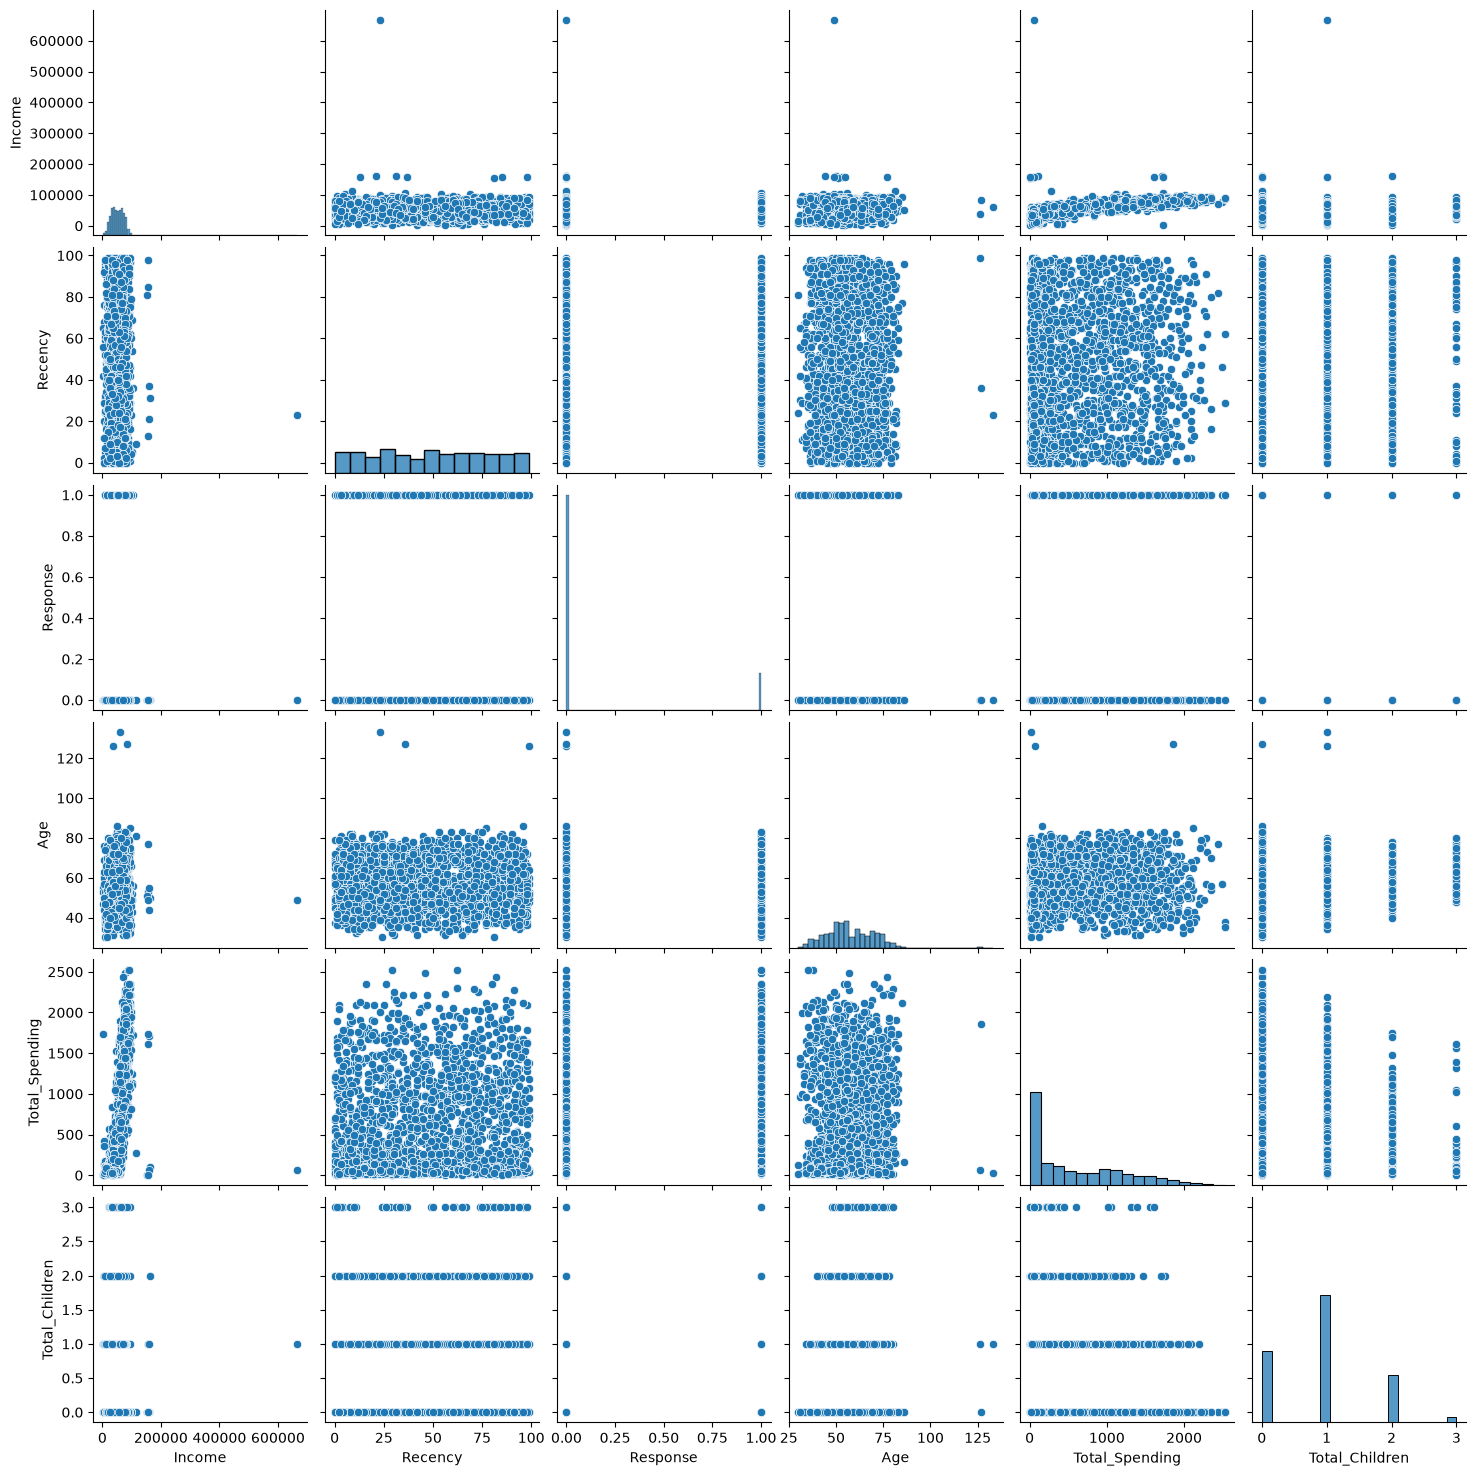

In [21]:
# Pair Plots (Relative Plots of some features)

sns.pairplot(df_cleaned[cols])

In [22]:
# Removing Outliers

print("Data Size with Outliers :", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print("Data Size without Outliers :", len(df_cleaned))

Data Size with Outliers : 2240
Data Size without Outliers : 2212


# Heatmap (For Better data insights) 

In [23]:
corr = df_cleaned.corr(numeric_only=True)

<Axes: >

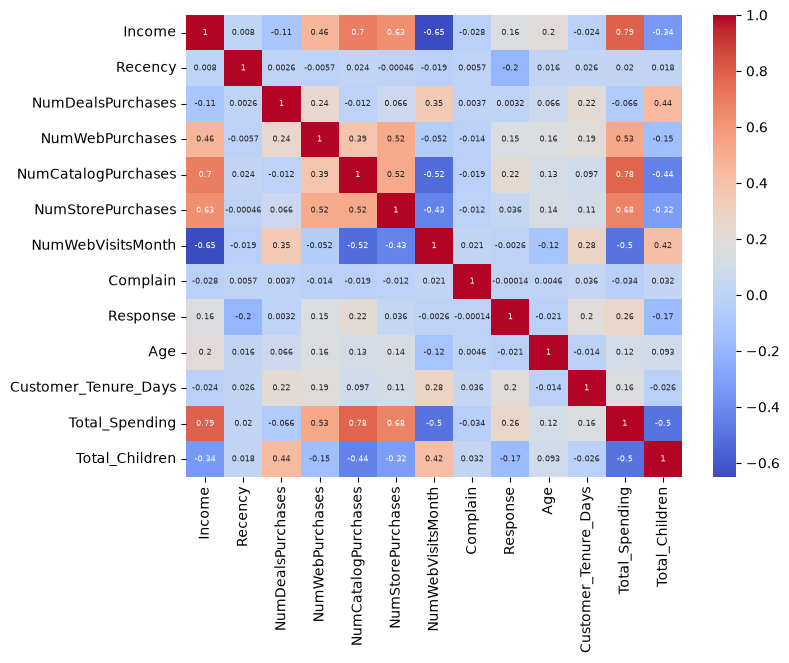

In [24]:
plt.figure(figsize = (8,6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size": 6},                                            # Used for resizing
    cmap = "coolwarm")

In [25]:
df_cleaned.shape

(2212, 15)

In [26]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Feature Encoding 

In [27]:
from sklearn.preprocessing import OneHotEncoder

In [28]:
ohe = OneHotEncoder()

cat_cols = ["Education","Living_With"]                                     #Categorical Features to be encoded

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [29]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns = ohe.get_feature_names_out(cat_cols),index = df_cleaned.index)

In [30]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [31]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols),enc_df],axis =1)

In [32]:
df_encoded.shape

(2212, 18)

In [33]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


# Scaling (Standardising the data)

In [34]:
from sklearn.preprocessing import StandardScaler

In [35]:
X = df_encoded

In [36]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [37]:
X_scaled

array([[ 0.28710487,  0.31035323,  0.35102992, ..., -0.35856858,
         1.34960312, -1.34960312],
       [-0.26088203, -0.38081349, -0.16870113, ..., -0.35856858,
         1.34960312, -1.34960312],
       [ 0.9131964 , -0.79551352, -0.68843217, ..., -0.35856858,
        -0.74095857,  0.74095857],
       ...,
       [ 0.23334696,  1.45077832, -0.68843217, ..., -0.35856858,
         1.34960312, -1.34960312],
       [ 0.80317156, -1.41756357, -0.16870113, ..., -0.35856858,
        -0.74095857,  0.74095857],
       [ 0.04229031, -0.31169682,  0.35102992, ..., -0.35856858,
        -0.74095857,  0.74095857]], shape=(2212, 18))

# Visualizing Data

In [38]:
X_scaled.shape

(2212, 18)

In [39]:
# 2D Visualization

from sklearn.decomposition import PCA

In [40]:
pca = PCA(n_components = 2)

X_pca = pca.fit_transform(X_scaled)

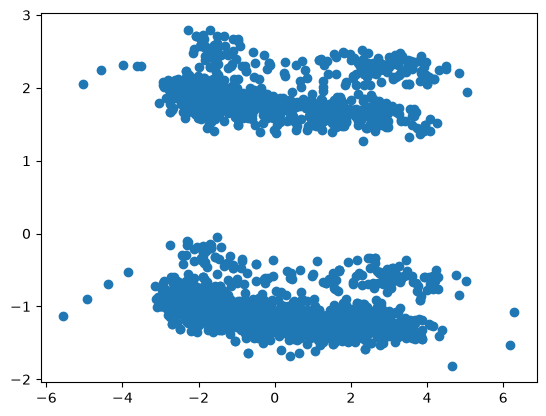

In [41]:
# Plotting

plt.scatter(X_pca[:,0],X_pca[:,1])

In [42]:
pca.explained_variance_ratio_

array([0.23258254, 0.11390916])

In [43]:
# 3D Visualisation

pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

In [44]:
pca.explained_variance_ratio_

array([0.23258254, 0.11390916, 0.10418299])

Text(0.5, 0.92, '3D Projections for all PCAs')

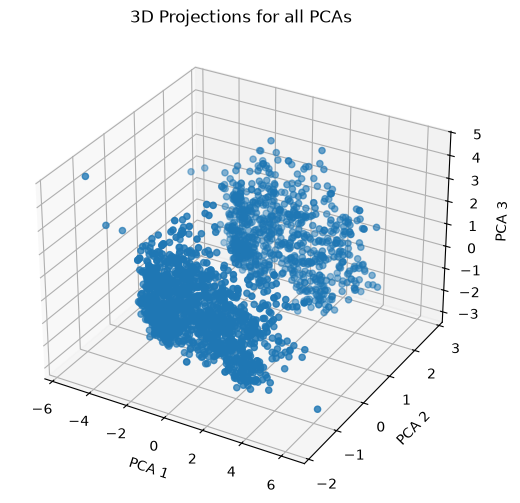

In [45]:
# Plotting

fig = plt.figure(figsize = (8,6))

ax = fig.add_subplot(111,projection = "3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])

ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
ax.set_title("3D Projections for all PCAs")

# Choosing K Value

In [46]:
# Elbow Method

from sklearn.cluster import KMeans
from kneed import KneeLocator

In [47]:
wcss = []

for k in range(1,11):
    kmeans=KMeans(n_clusters = k,random_state = 42)
    kmeans.fit_transform(X_pca)
    wcss.append(kmeans.inertia_)

In [48]:
knee = KneeLocator(range(1,11),wcss,curve = "convex",direction = "decreasing")

optimal_K = knee.elbow

In [49]:
print("Best K value = ",optimal_K)

Best K value =  4


Text(0.5, 0, 'WCSS')

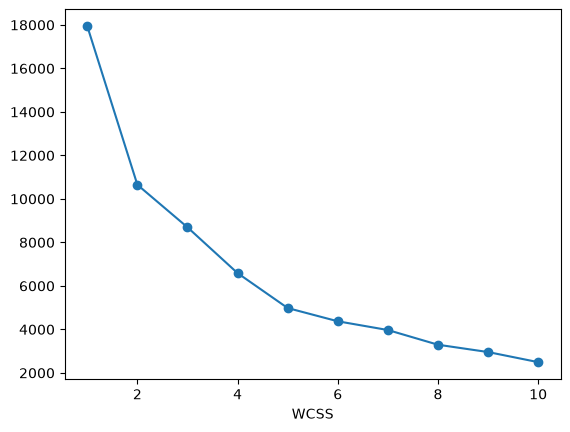

In [50]:
# Plot

plt.plot(range(1,11),wcss, marker ='o')
plt.xlabel("K")
plt.xlabel("WCSS")

In [51]:
# Silhouette Score

from sklearn.metrics import silhouette_score

scores = []

for k in range (2,11):
    kmeans = KMeans(n_clusters = k , random_state = 42)
    label = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca , label)
    scores.append(score)

Text(0.5, 0, 'Silhouette Score')

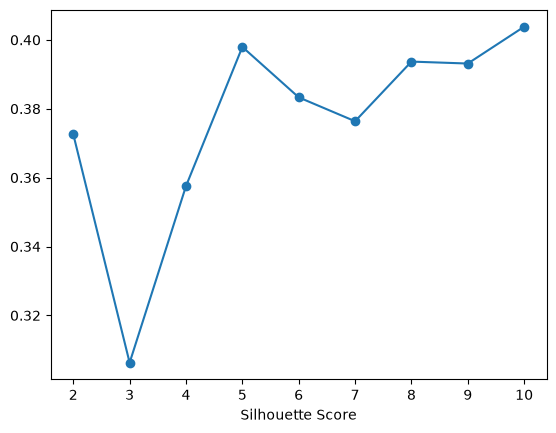

In [52]:
#Plotting 

plt.plot(range(2,11),scores, marker ='o')
plt.xlabel("K")
plt.xlabel("Silhouette Score")

Text(0, 0.5, 'SS')

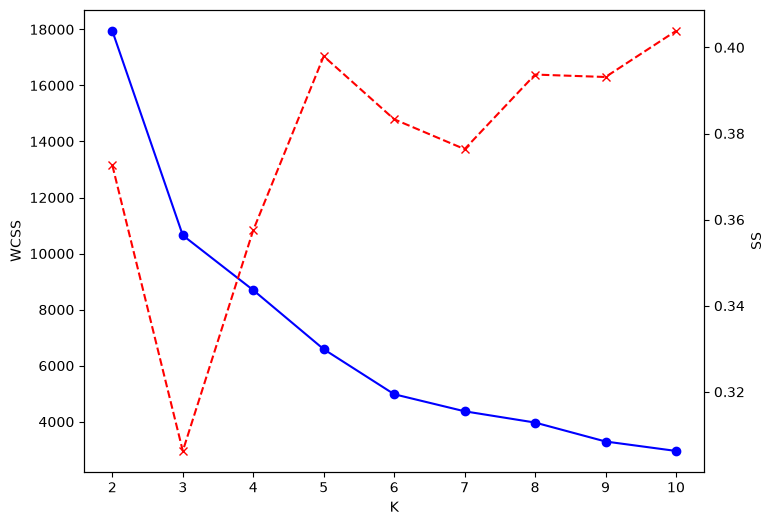

In [53]:
# Combined Plot (K vs WCSS)

k_range = range(2,11)

fig,ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k_range,wcss[:len(k_range)],marker = "o", color ="blue")

ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker = "x",color = "red",linestyle = "--")
ax2.set_ylabel("SS")

# Clustering

In [54]:
# K-Means

kmeans = KMeans(n_clusters = 4,random_state = 42)
labels_kmeans = kmeans.fit_predict(X_pca) 

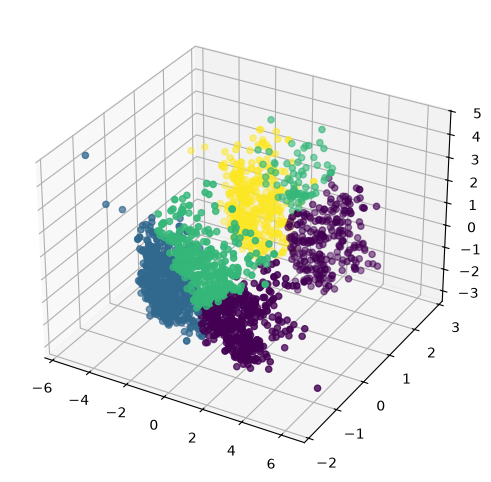

In [55]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c = labels_kmeans)

In [56]:
#Agglomerative Clustering

from sklearn.cluster import AgglomerativeClustering

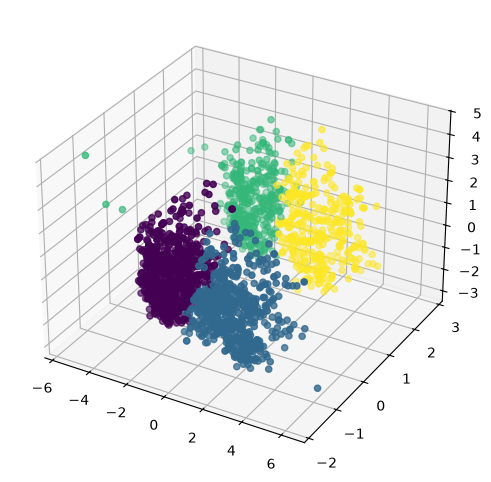

In [57]:
agg_cl = AgglomerativeClustering(n_clusters = 4, linkage = "ward")
labels_agg = agg_cl.fit_predict(X_pca)

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c = labels_agg)

##### Agglomerative Clustering is thus the best clustering here as it clearly seperates data into four clusters (DBSCAN returns 30+ clusters)

# Characterization of Clusters

In [74]:
df_cleaned["Cluster"] = labels_agg

In [75]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With,labels,cluster,Cluster
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3,3,3
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2,2,2
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner,1,1,1
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner,0,0,0
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner,0,0,0


<Axes: xlabel='Cluster', ylabel='count'>

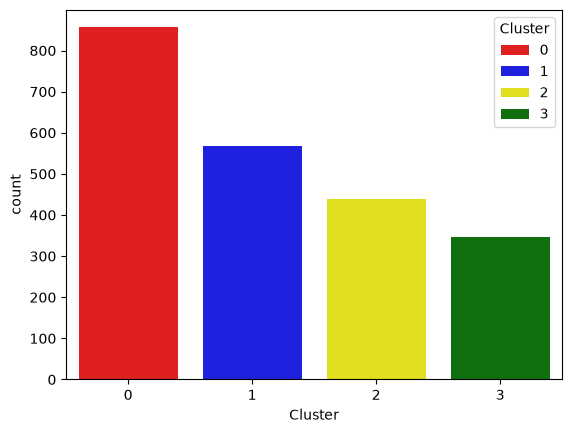

In [81]:
pal = ["red","blue","yellow","green"]

sns.countplot(x=df_cleaned["Cluster"],palette = pal, hue = df_cleaned["Cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

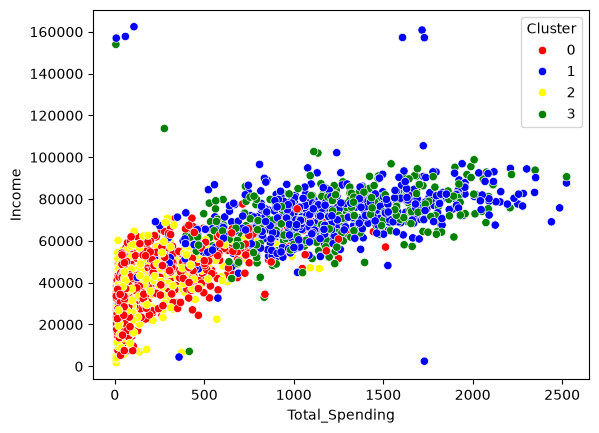

In [80]:
# Income and Spending Pattern

sns.scatterplot(x=df_cleaned["Total_Spending"],y=df_cleaned["Income"],hue = df_cleaned["Cluster"],palette = pal)

# Cluster Summary

In [86]:
X["Cluster"] = labels_agg

pal = ["red","blue","yellow","green"]

cluster_summary = X.groupby("Cluster").mean()
print (cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
Cluster                                                                
0        38814.688084  49.113318           2.643692         3.063084   
1        71785.449912  48.810193           1.919156         5.662566   
2        36861.452273  48.034091           2.600000         2.736364   
3        71016.011527  50.380403           1.853026         5.749280   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Cluster                                                                        
0                   0.941589           4.070093           6.477804  0.009346   
1                   5.230228           8.469244           3.520211  0.008787   
2                   0.854545           3.643182           6.659091  0.011364   
3                   5.051873           8.466859           3.726225  0.005764   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
Cluster         

### (Several Data Insights can then be inferred from the above mean table) 